<a href="https://colab.research.google.com/github/RealHotnCold/MLA0204-192511036/blob/main/ANN_using_Backpropogation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Artificial Neural Network with Backpropagation

This notebook demonstrates a complete implementation of a multi-layer feedforward Artificial Neural Network (ANN) with the Backpropagation training algorithm built from scratch using NumPy. We will test the network on a classic classification dataset.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

# Set random seed for reproducibility
np.random.seed(42)

## 1. ANN and Backpropagation Class Implementation

Below is the Python class defining the neural network structure, forward propagation, backpropagation, and training loop.

In [2]:
class NeuralNetwork:
    def __init__(self, layers, learning_rate=0.1):
        """
        layers: list containing the number of neurons in each layer (e.g., [2, 4, 2])
        learning_rate: step size for gradient descent parameter updates
        """
        self.layers = layers
        self.learning_rate = learning_rate
        self.weights = []
        self.biases = []

        # Initialize weights and biases randomly
        for i in range(len(layers) - 1):
            # He/Glorot-like initialization scales weights appropriately
            w = np.random.randn(layers[i], layers[i+1]) * np.sqrt(2.0 / layers[i])
            b = np.zeros((1, layers[i+1]))
            self.weights.append(w)
            self.biases.append(b)

    def sigmoid(self, z):
        return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

    def sigmoid_derivative(self, a):
        # a is sigmoid(z)
        return a * (1.0 - a)

    def forward(self, X):
        """
        Compute forward pass.
        X: input data of shape (num_samples, num_features)
        """
        self.activations = [X]
        self.zs = []

        a = X
        for i in range(len(self.weights)):
            z = np.dot(a, self.weights[i]) + self.biases[i]
            self.zs.append(z)
            a = self.sigmoid(z)
            self.activations.append(a)
        return a

    def backward(self, X, y):
        """
        Compute gradients using Backpropagation and update weights/biases.
        X: inputs
        y: true labels (one-hot encoded)
        """
        m = X.shape[0]

        # Output layer error
        # Cost function: Mean Squared Error gradient
        # dC/da * da/dz
        error = self.activations[-1] - y
        delta = error * self.sigmoid_derivative(self.activations[-1])

        # Gradients for output layer weights and biases
        dW = np.dot(self.activations[-2].T, delta) / m
        dB = np.sum(delta, axis=0, keepdims=True) / m

        # Store updates to apply after parsing all layers
        updates = [(dW, dB)]

        # Backpropagate through hidden layers
        for l in range(len(self.layers) - 2, 0, -1):
            delta = np.dot(delta, self.weights[l].T) * self.sigmoid_derivative(self.activations[l])
            dW = np.dot(self.activations[l-1].T, delta) / m
            dB = np.sum(delta, axis=0, keepdims=True) / m
            updates.insert(0, (dW, dB))

        # Update parameters
        for i in range(len(self.weights)):
            self.weights[i] -= self.learning_rate * updates[i][0]
            self.biases[i] -= self.learning_rate * updates[i][1]

    def train(self, X, y, epochs=1000):
        loss_history = []
        for epoch in range(epochs):
            # Forward pass
            predictions = self.forward(X)

            # Calculate Mean Squared Error loss
            loss = np.mean((predictions - y) ** 2)
            loss_history.append(loss)

            # Backpropagation and Parameter Update
            self.backward(X, y)

            if (epoch + 1) % (epochs // 10 or 1) == 0 or epoch == 0:
                print(f"Epoch {epoch+1}/{epochs} - Loss: {loss:.4f}")
        return loss_history

## 2. Testing the ANN on a Dataset

We will generate a non-linearly separable dataset (the Moons dataset) to challenge and showcase our backpropagation neural network.

In [3]:
# Generate Synthetic Moons data
X, y = make_moons(n_samples=500, noise=0.2, random_state=42)

# One-hot encode the target labels for multi-class structure representation
encoder = OneHotEncoder(sparse_output=False)
y_onehot = encoder.fit_transform(y.reshape(-1, 1))

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y_onehot, test_size=0.3, random_state=42)

# Instantiate the ANN: 2 input nodes, 8 hidden layer nodes, 2 output nodes
layers = [2, 8, 2]
ann = NeuralNetwork(layers=layers, learning_rate=0.5)

# Train the network
loss_history = ann.train(X_train, y_train, epochs=2000)

Epoch 1/2000 - Loss: 0.2519
Epoch 200/2000 - Loss: 0.1093
Epoch 400/2000 - Loss: 0.0974
Epoch 600/2000 - Loss: 0.0943
Epoch 800/2000 - Loss: 0.0932
Epoch 1000/2000 - Loss: 0.0927
Epoch 1200/2000 - Loss: 0.0924
Epoch 1400/2000 - Loss: 0.0922
Epoch 1600/2000 - Loss: 0.0920
Epoch 1800/2000 - Loss: 0.0918
Epoch 2000/2000 - Loss: 0.0916


## 3. Evaluation and Visualization

Let's plot the training loss curve and visualize how the trained network partitions the feature space.

Test Accuracy: 86.67%


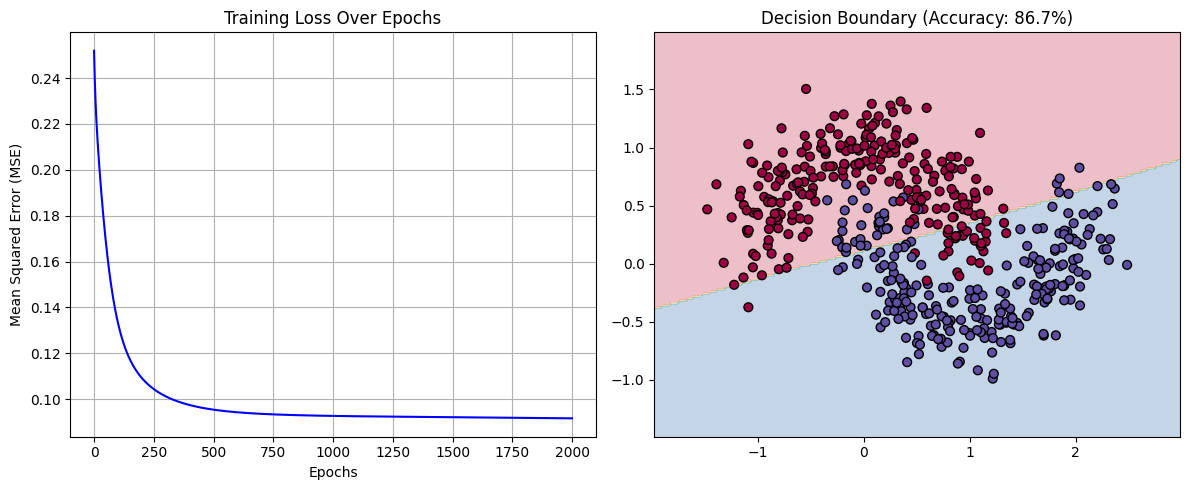

In [4]:
# Plot learning curve
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(loss_history, color='blue')
plt.title("Training Loss Over Epochs")
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error (MSE)")
plt.grid(True)

# Predict on test set
test_predictions = ann.forward(X_test)
y_pred_classes = np.argmax(test_predictions, axis=1)
y_true_classes = np.argmax(y_test, axis=1)
accuracy = np.mean(y_pred_classes == y_true_classes) * 100
print(f"Test Accuracy: {accuracy:.2f}%")

# Plot Decision Boundary
plt.subplot(1, 2, 2)
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

grid_points = np.c_[xx.ravel(), yy.ravel()]
grid_predictions = ann.forward(grid_points)
Z = np.argmax(grid_predictions, axis=1)
Z = Z.reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.Spectral)
plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.Spectral, edgecolor='k')
plt.title(f"Decision Boundary (Accuracy: {accuracy:.1f}%)")
plt.tight_layout()
plt.show()